# EDA 10 · Redundancy and unified feature ranking

**Part II · Engineered features** · part of the 10-notebook EDA series in `workshops/w1/eda/` (index in `README.md`).

**Question.** Which features are redundant, and what is the unified ranking of all 59 features?

**Data.** Exported tabular table `export-tabular-v5/train_feb.parquet`: the February development cohort, 992,931 customers x 59 features, 6.39 % churn. Figures are written to `workshops/w1/figures/eda/`.

**How to read it.** The Spearman matrix shows blocks of near-duplicate features; mutual information puts every feature type on one scale.

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

# Paths resolve from the w1 folder, whether the notebook runs from workshops/w1 or workshops/w1/eda.
W1_DIR = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent

# February development cohort (cutoff 2017-01-31). Use "test" for the March cohort.
COHORT = "train_feb"

ON_KAGGLE = Path("/kaggle/input").exists()
DATA_CANDIDATES = [
    Path("/kaggle/input/dataset-final"),
    W1_DIR / "export-tabular-v5",
    Path("export-tabular-v5"),
]
DATA_DIR = next(
    (path.resolve() for path in DATA_CANDIDATES if (path / f"{COHORT}.parquet").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        f"{COHORT}.parquet not found in: {', '.join(map(str, DATA_CANDIDATES))}. "
        "Generate it with workshops/w1/w1_data_preprocessing.ipynb."
    )

# The 59 model features and the nominal ones come from the w1 preprocessing state;
# on Kaggle the export metadata provides the same catalogue.
STATE_PATH = W1_DIR / "artifacts" / "sherlock_w1" / "preprocessing" / "development.json"
state_path = STATE_PATH if STATE_PATH.exists() else DATA_DIR / "metadata.json"
state = json.loads(state_path.read_text())
FEATURES = state["features"]
CATEGORICAL = state["categorical"]

GRAPHICS_DIR = (Path("/kaggle/working") if ON_KAGGLE else W1_DIR) / "figures" / "eda"
GRAPHICS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_DIR / f"{COHORT}.parquet", columns=["msno", "is_churn"] + FEATURES)
assert df["msno"].is_unique, "expected one row per customer"
y = df["is_churn"].astype(int)

print(f"Source: {DATA_DIR / f'{COHORT}.parquet'}")
print(f"Feature catalogue: {state_path}")
print(f"Shape: {df.shape[0]:,} customers x {len(FEATURES)} features (+ msno, is_churn)")
display(df.head())

In [ ]:
DOMAIN_STARTS = {"member": "city", "transactions": "is_cancel_change_flag", "logs": "sum_last_month_unq"}
starts = sorted((FEATURES.index(first), name) for name, first in DOMAIN_STARTS.items())
DOMAIN = {}
for (start, name), (end, _) in zip(starts, starts[1:] + [(len(FEATURES), None)]):
    DOMAIN.update({feature: name for feature in FEATURES[start:end]})


def feature_type(series, name):
    values = series.dropna()
    n_unique = values.nunique()
    if name in CATEGORICAL:
        return "categorical"
    if n_unique <= 1:
        return "constant"
    if n_unique == 2:
        return "binary"
    if n_unique <= 31 and np.allclose(values, np.round(values)):
        return "discrete"
    return "continuous"


catalogue = pd.DataFrame({
    "domain": [DOMAIN[f] for f in FEATURES],
    "type": [feature_type(df[f], f) for f in FEATURES],
    "dtype": [str(df[f].dtype) for f in FEATURES],
    "n_unique": [df[f].nunique() for f in FEATURES],
    "missing_pct": [df[f].isna().mean() * 100 for f in FEATURES],
}, index=pd.Index(FEATURES, name="feature"))

TYPES = {kind: catalogue.index[catalogue["type"].eq(kind)].tolist()
         for kind in ["categorical", "binary", "discrete", "continuous", "constant"]}
NUMERIC = TYPES["binary"] + TYPES["discrete"] + TYPES["continuous"]

display(pd.crosstab(catalogue["domain"], catalogue["type"], margins=True))
display(catalogue.round(2))
if TYPES["constant"]:
    print("Constant features (no information about churn):", TYPES["constant"])

In [ ]:
# Plot settings shared by the relationship figures (same values as in notebook 07).
import matplotlib.pyplot as plt

churn_labels = ["No", "Yes"]
churn_colors = ["#4b8f8c", "#d66b4e"]
BASE_RATE = y.mean()  # overall churn rate, drawn as the dashed line in the figures

### Recomputed inputs

The ranking needs the Pearson/Spearman/AUC table and Cramér's V. The cells below recompute them with the same code as notebook 08 (outputs omitted here; see notebook 08 for the plots).

In [ ]:
from sklearn.metrics import roc_auc_score


def univariate_auc(values):
    mask = values.notna()
    return roc_auc_score(y[mask], values[mask])


numeric_corr = pd.DataFrame({
    "domain": catalogue.loc[NUMERIC, "domain"],
    "type": catalogue.loc[NUMERIC, "type"],
    "pearson": df[NUMERIC].corrwith(y),
    "spearman": df[NUMERIC].corrwith(y, method="spearman"),
    "roc_auc": [univariate_auc(df[f]) for f in NUMERIC],
})
numeric_corr = numeric_corr.reindex(numeric_corr["spearman"].abs().sort_values(ascending=False).index)
display(numeric_corr.round(4))

order = numeric_corr.index[::-1]
positions = np.arange(len(order))
bar_height = 0.4
fig, ax = plt.subplots(figsize=(9, 0.25 * len(order) + 1.5))
ax.barh(positions + bar_height / 2, numeric_corr.loc[order, "spearman"], bar_height,
        label="Spearman", color="#2f5d8a")
ax.barh(positions - bar_height / 2, numeric_corr.loc[order, "pearson"], bar_height,
        label="Pearson", color="#a9b8c6")
ax.set_yticks(positions, labels=order, fontsize=8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title=f"Correlation with is_churn ({COHORT})", xlabel="Correlation coefficient")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "churn_numeric_correlations.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

In [ ]:
from scipy.stats import chi2_contingency

MAX_LEVELS = 12


def as_levels(series):
    labels = series.astype("Int64").astype("string").fillna("missing")
    top = labels.value_counts().index[:MAX_LEVELS]
    return labels.where(labels.isin(top), "other")


def cramers_v(table):
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    rows, cols = table.shape
    phi2 = max(0.0, chi2 / n - (rows - 1) * (cols - 1) / (n - 1))
    rows_c = rows - (rows - 1) ** 2 / (n - 1)
    cols_c = cols - (cols - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(rows_c - 1, cols_c - 1))


categorical_assoc = pd.DataFrame({
    "domain": catalogue.loc[TYPES["categorical"], "domain"],
    "n_levels": catalogue.loc[TYPES["categorical"], "n_unique"],
    "cramers_v": [
        cramers_v(pd.crosstab(df[f].astype("Int64").astype("string").fillna("missing"), y))
        for f in TYPES["categorical"]
    ],
}).sort_values("cramers_v", ascending=False)
display(categorical_assoc.round(4))

fig, axes = plt.subplots(len(TYPES["categorical"]), 1,
                         figsize=(11, 3.6 * len(TYPES["categorical"])), squeeze=False)
for axis, feature in zip(axes.flat, TYPES["categorical"]):
    levels = as_levels(df[feature])
    stats = y.groupby(levels).agg(["mean", "size"]).sort_values("size", ascending=False)
    bars = axis.bar(stats.index, stats["mean"] * 100, color=churn_colors[1])
    axis.axhline(BASE_RATE * 100, color="black", linestyle="--", linewidth=1, label="overall rate")
    axis.bar_label(bars, labels=[f"{r:.1%}\nn={n:,}" for r, n in zip(stats["mean"], stats["size"])],
                   padding=1, fontsize=7)
    axis.set_title(f"{feature} (levels sorted by customers)")
    axis.set_ylabel("Churn rate (%)")
    axis.set_ylim(0, stats["mean"].max() * 100 * 1.3)
    axis.grid(axis="y", alpha=0.25)
    axis.set_axisbelow(True)
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "churn_categorical_relationships.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

### Analysis

## Correlation between features

Many engineered features are built from the same raw fields (sums, averages and last values of the same
transaction columns, or consecutive months of the same listening counts), so some are near-duplicates.
The Spearman matrix below, computed on a stratified sample for speed, shows these blocks; pairs with
|ρ| ≥ 0.9 are listed as redundancy candidates.

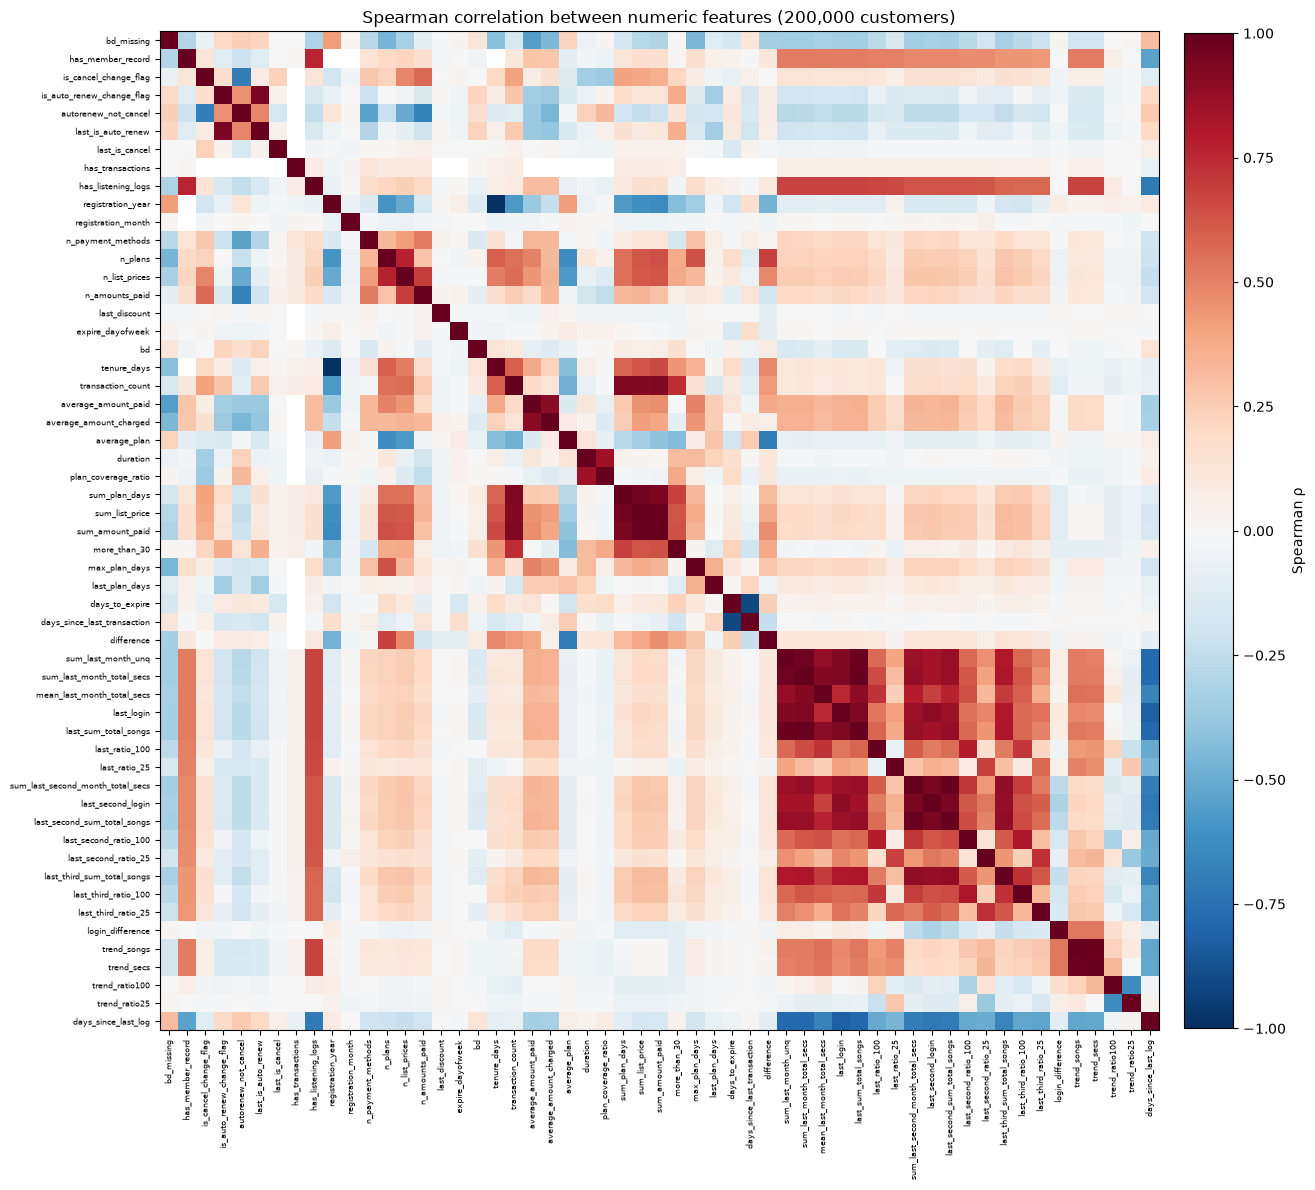

Pairs with |rho| >= 0.9: 21


,feature_a,feature_b,spearman,churn_spearman_a,churn_spearman_b
0,sum_last_second_month_total_secs,last_second_sum_total_songs,0.992,-0.033,-0.031
1,sum_last_month_total_secs,last_sum_total_songs,0.991,-0.013,-0.011
2,registration_year,tenure_days,-0.988,0.025,-0.021
3,sum_list_price,sum_amount_paid,0.987,-0.060,-0.065
4,sum_last_month_unq,last_sum_total_songs,0.983,-0.010,-0.011
5,trend_songs,trend_secs,0.980,0.022,0.022
6,sum_last_month_unq,sum_last_month_total_secs,0.973,-0.010,-0.013
7,sum_plan_days,sum_list_price,0.961,-0.079,-0.060
8,last_second_login,last_second_sum_total_songs,0.945,-0.037,-0.031
9,sum_plan_days,sum_amount_paid,0.941,-0.079,-0.065


In [9]:
SAMPLE_SIZE = 200_000
SEED = 42

sample = df.groupby("is_churn", group_keys=False).sample(
    frac=min(1.0, SAMPLE_SIZE / len(df)), random_state=SEED
)
feature_corr = sample[NUMERIC].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 12))
image = ax.imshow(feature_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(NUMERIC)), labels=NUMERIC, rotation=90, fontsize=6)
ax.set_yticks(np.arange(len(NUMERIC)), labels=NUMERIC, fontsize=6)
ax.set_title(f"Spearman correlation between numeric features ({len(sample):,} customers)")
fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02, label="Spearman ρ")
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "feature_correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

upper = feature_corr.where(np.triu(np.ones(feature_corr.shape, dtype=bool), k=1))
redundant = upper.stack().rename("spearman").reset_index()
redundant.columns = ["feature_a", "feature_b", "spearman"]
redundant = redundant[redundant["spearman"].abs().ge(0.9)]
redundant = redundant.reindex(redundant["spearman"].abs().sort_values(ascending=False).index)
redundant["churn_spearman_a"] = numeric_corr.loc[redundant["feature_a"], "spearman"].to_numpy()
redundant["churn_spearman_b"] = numeric_corr.loc[redundant["feature_b"], "spearman"].to_numpy()
print(f"Pairs with |rho| >= 0.9: {len(redundant)}")
display(redundant.round(3).reset_index(drop=True))

## Unified ranking: mutual information

Correlation coefficients and Cramér's V are not on the same scale, so the final ranking uses **mutual
information** with the target, which applies to every feature type and also captures non-monotonic
relationships. It is estimated on the same stratified sample; categorical, binary and discrete features are
treated as discrete, and missing values are filled with the median (numeric) or a separate code (categorical).
The table joins all the measures computed above.

,rank,domain,type,missing_pct,pearson,spearman,roc_auc,cramers_v,mutual_info
feature,,,,,,,,,
last_plan_days,1,transactions,continuous,0.2110,0.2445,0.2099,0.5692,NaN,0.0487
duration,2,transactions,continuous,0.2110,0.1531,0.0507,0.5600,NaN,0.0442
last_payment_method_id,3,transactions,categorical,0.2110,NaN,NaN,NaN,0.3792,0.0434
last_is_auto_renew,4,transactions,binary,0.2110,-0.3777,-0.3777,0.2548,NaN,0.0432
average_amount_charged,5,transactions,continuous,0.2110,0.2343,0.1715,0.6991,NaN,0.0415
average_amount_paid,6,transactions,continuous,0.2110,0.2287,0.1480,0.6690,NaN,0.0401
sum_amount_paid,7,transactions,continuous,0.0000,-0.0637,-0.0655,0.4228,NaN,0.0393
average_plan,8,transactions,continuous,0.2110,0.2243,0.0860,0.5908,NaN,0.0390
plan_coverage_ratio,9,transactions,continuous,0.2112,0.0789,-0.0143,0.4831,NaN,0.0387


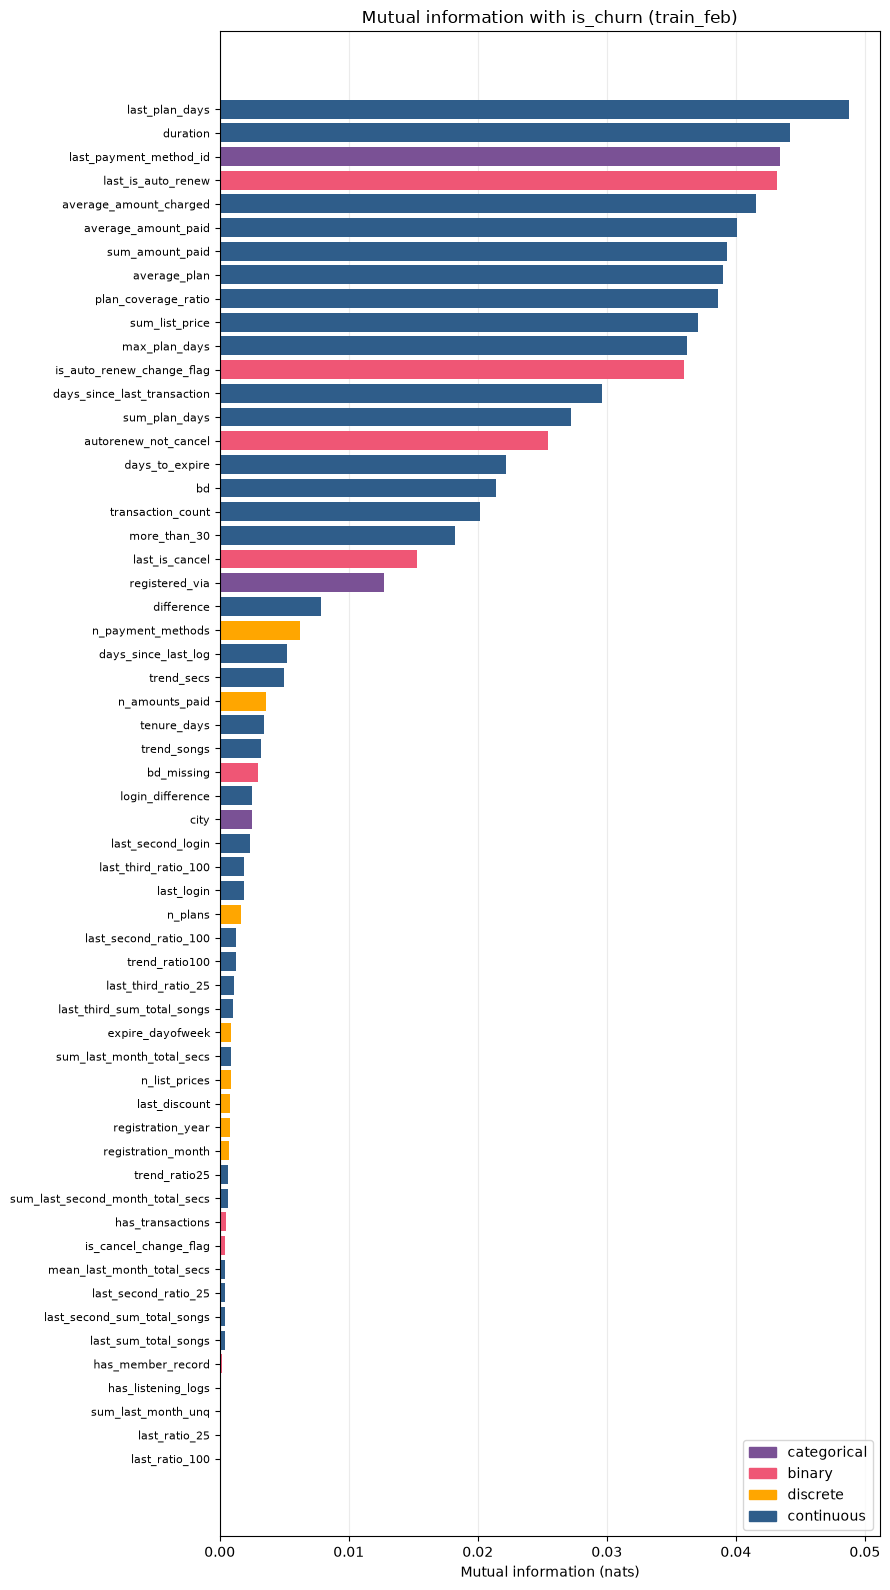

Top transactions features: last_plan_days, duration, last_payment_method_id, last_is_auto_renew, average_amount_charged
Top member features: bd, registered_via, tenure_days, bd_missing, city
Top logs features: days_since_last_log, trend_secs, trend_songs, login_difference, last_second_login


In [10]:
from sklearn.feature_selection import mutual_info_classif

ranked = TYPES["categorical"] + NUMERIC
X_sample = sample[ranked].copy()
for feature in TYPES["categorical"]:
    X_sample[feature] = X_sample[feature].fillna(-1)
X_sample[NUMERIC] = X_sample[NUMERIC].fillna(X_sample[NUMERIC].median())
discrete_mask = [feature not in TYPES["continuous"] for feature in ranked]

mutual_info = pd.Series(
    mutual_info_classif(X_sample.to_numpy(dtype=float), sample["is_churn"].to_numpy(),
                        discrete_features=discrete_mask, random_state=SEED),
    index=ranked, name="mutual_info",
)

feature_ranking = (
    catalogue.loc[ranked, ["domain", "type", "missing_pct"]]
    .join(numeric_corr[["pearson", "spearman", "roc_auc"]])
    .join(categorical_assoc[["cramers_v"]])
    .join(mutual_info)
    .sort_values("mutual_info", ascending=False)
)
feature_ranking.insert(0, "rank", np.arange(1, len(feature_ranking) + 1))
display(feature_ranking.round(4))
feature_ranking.to_csv(GRAPHICS_DIR / "feature_churn_ranking.csv")

type_colors = {"categorical": "#7a5195", "binary": "#ef5675", "discrete": "#ffa600", "continuous": "#2f5d8a"}
order = feature_ranking.index[::-1]
fig, ax = plt.subplots(figsize=(9, 0.25 * len(order) + 1.5))
ax.barh(order, feature_ranking.loc[order, "mutual_info"],
        color=[type_colors[t] for t in feature_ranking.loc[order, "type"]])
ax.tick_params(axis="y", labelsize=8)
ax.set(title=f"Mutual information with is_churn ({COHORT})", xlabel="Mutual information (nats)")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in type_colors.values()],
          labels=list(type_colors), loc="lower right")
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "churn_mutual_information.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

for domain, group in feature_ranking.groupby("domain", sort=False):
    print(f"Top {domain} features:", ", ".join(group.index[:5]))

## Findings

- **Target.** The cohort churn rate is 6.39 % (14.64:1 imbalance); the March test cohort is 8.99 %.
- **Strongest signals.** The top 20 features by mutual information are all transaction features except `bd` (rank 17).
  The top ten are `last_plan_days` (0.0487), `duration` (0.0442), `last_payment_method_id` (0.0434),
  `last_is_auto_renew` (0.0432), `average_amount_charged` (0.0415), `average_amount_paid` (0.0401),
  `sum_amount_paid` (0.0393), `average_plan` (0.0390), `plan_coverage_ratio` (0.0387) and `sum_list_price` (0.0371).
  The best listening feature is `days_since_last_log`, at rank 24 (0.0052).
- **Non-linear patterns.** `plan_coverage_ratio` has |Spearman| of only 0.014 and a ROC AUC of 0.483, yet ranks 9th by mutual
  information: the relationship is non-monotonic and correlation alone would discard it.
- **Categorical levels.** See notebook 08: `last_payment_method_id` levels range from 0.9 % to 51.4 % churn.
- **Redundancy.** 21 feature pairs have |ρ| >= 0.9, for example `sum_last_second_month_total_secs` with
  `last_second_sum_total_songs` (0.992), `registration_year` with `tenure_days` (-0.988), `sum_list_price` with
  `sum_amount_paid` (0.987) and `trend_songs` with `trend_secs` (0.980).
- **Weak features.** `has_listening_logs`, `sum_last_month_unq`, `last_ratio_25` and `last_ratio_100` have mutual
  information of about 0.
- **Caveat.** Mutual information is estimated on a stratified sample of 200,000 customers; these are associations in this
  cohort, not causal effects.

---
**Previous:** `09_binary_discrete_continuous_vs_churn.ipynb` · **Next:** none (end of the EDA series); modelling starts in `../w1_tabular_models.ipynb`